# Demo notebook

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from src.data_loader import load_data
from src.preprocessor import clean_data, remove_outliner ,preprocess_data
from src.eda import select_categorical_variable, select_numberical_variable, plot_single_boxplot, plot_anova, get_num_cat_var, numeric_var_statistic, categorical_var_statistic
from src.model_pipeline import train_data_pipeline

In [2]:
raw_df = load_data("laptop_price.csv")
raw_df.head(10)

[THÀNH CÔNG] Đã tải dữ liệu. Kích thước: 1303 dòng, 13 cột.


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60
5,6,Acer,Aspire 3,Notebook,15.6,1366x768,AMD A9-Series 9420 3GHz,4GB,500GB HDD,AMD Radeon R5,Windows 10,2.1kg,400.00
6,7,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.2GHz,16GB,256GB Flash Storage,Intel Iris Pro Graphics,Mac OS X,2.04kg,2139.97
7,8,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,256GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,1158.70
8,9,Asus,ZenBook UX430UN,Ultrabook,14.0,Full HD 1920x1080,Intel Core i7 8550U 1.8GHz,16GB,512GB SSD,Nvidia GeForce MX150,Windows 10,1.3kg,1495.00
9,10,Acer,Swift 3,Ultrabook,14.0,IPS Panel Full HD 1920x1080,Intel Core i5 8250U 1.6GHz,8GB,256GB SSD,Intel UHD Graphics 620,Windows 10,1.6kg,770.00


In [4]:
df = clean_data(raw_df)
df.head(3)

Đang tiến hành làm sạch dữ liệu...
[THÀNH CÔNG] Làm sạch dữ liệu hoàn tất! Kích thước: 1303 dòng, 18 cột.


,Company,TypeName,Inches,Ram,OpSys,Weight,Price_euros,Touchscreen,Ips,Resolution,Cpu_Speed,Cpu_Brand,SSD,HDD,Flash_Storage,Hybrid,Gpu_Brand,Gpu_Type
0,Apple,Ultrabook,13.3,8,macOS,1.37,1339.69,0,1,2560x1600,2.3,Intel Core i5,128,0,0,0,Intel,Intel Integrated Graphics
1,Apple,Ultrabook,13.3,8,macOS,1.34,898.94,0,0,1440x900,1.8,Intel Core i5,0,0,128,0,Intel,Intel Integrated Graphics
2,HP,Notebook,15.6,8,No OS,1.86,575.00,0,0,1920x1080,2.5,Intel Core i5,256,0,0,0,Intel,Intel Integrated Graphics


In [5]:
numerical_cols, categorical_cols = get_num_cat_var(df)

Các biến số: ['Inches', 'Ram', 'Weight', 'Price_euros', 'Touchscreen', 'Ips', 'Cpu_Speed', 'SSD', 'HDD', 'Flash_Storage', 'Hybrid']
Các biến phân loại: ['Company', 'TypeName', 'OpSys', 'Resolution', 'Cpu_Brand', 'Gpu_Brand', 'Gpu_Type']


=== THỐNG KÊ MÔ TẢ CÁC BIẾN SỐ ===
                count         mean         std     min    25%     50%  \
Inches         1303.0    15.017191    1.426304   10.10   14.0   15.60   
Ram            1303.0     8.382195    5.084665    2.00    4.0    8.00   
Weight         1303.0     2.038734    0.665475    0.69    1.5    2.04   
Price_euros    1303.0  1123.686992  699.009043  174.00  599.0  977.00   
Touchscreen    1303.0     0.147352    0.354593    0.00    0.0    0.00   
Ips            1303.0     0.280123    0.449231    0.00    0.0    0.00   
Cpu_Speed      1303.0     2.298772    0.506340    0.90    2.0    2.50   
SSD            1303.0   183.732924  186.966903    0.00    0.0  256.00   
HDD            1303.0   413.783576  515.818779    0.00    0.0    0.00   
Flash_Storage  1303.0     4.555641   30.274090    0.00    0.0    0.00   
Hybrid         1303.0     8.831926   92.567185    0.00    0.0    0.00   

                   75%     max  
Inches           15.60    18.4  
Ram               8.00

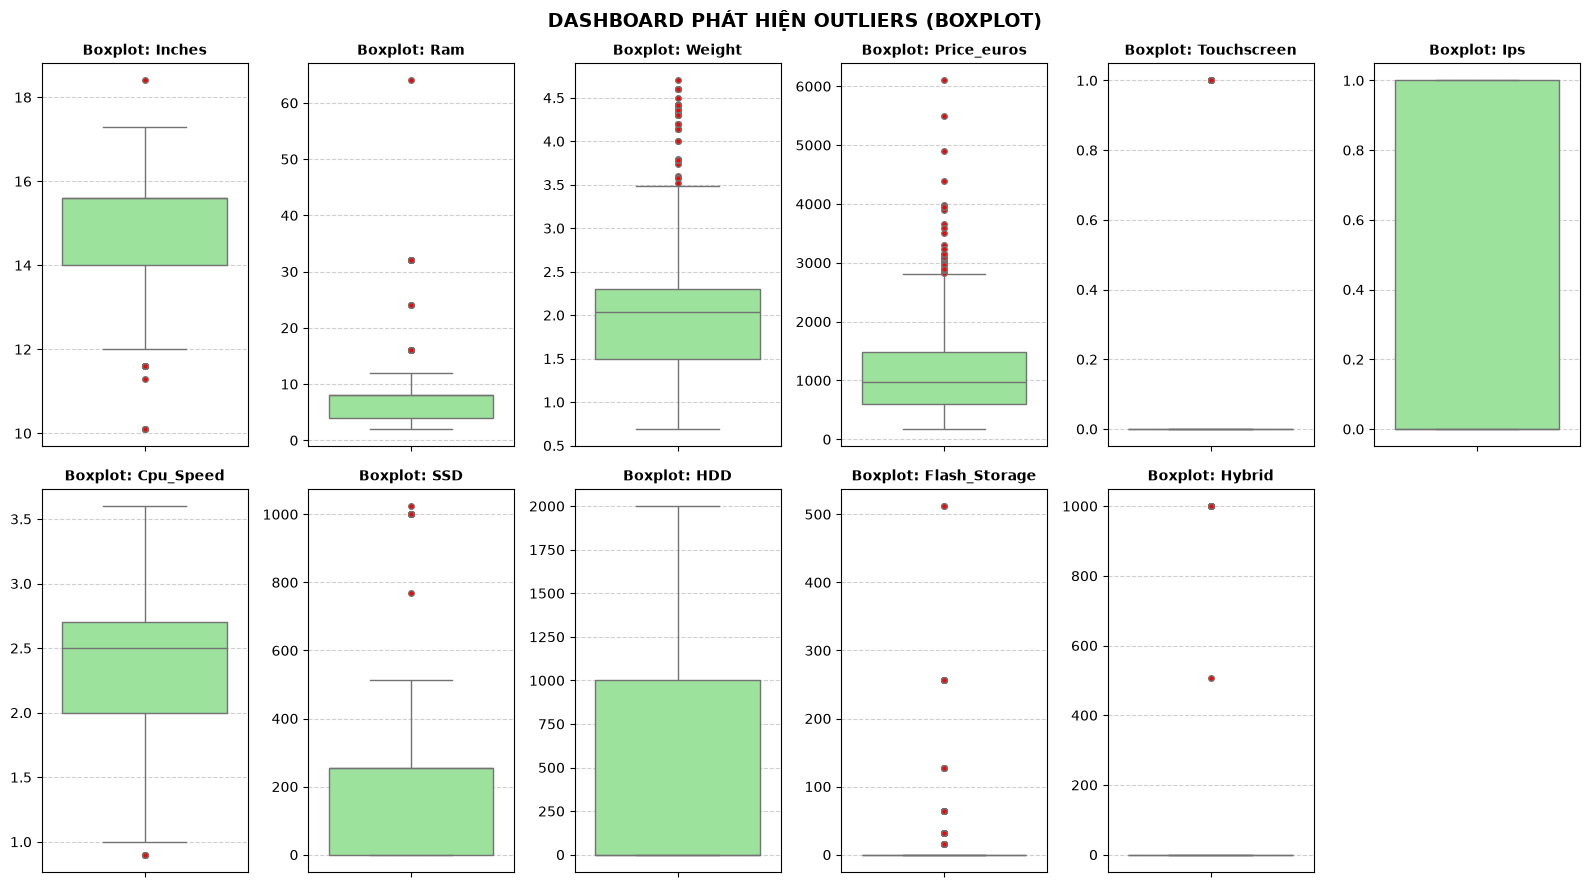

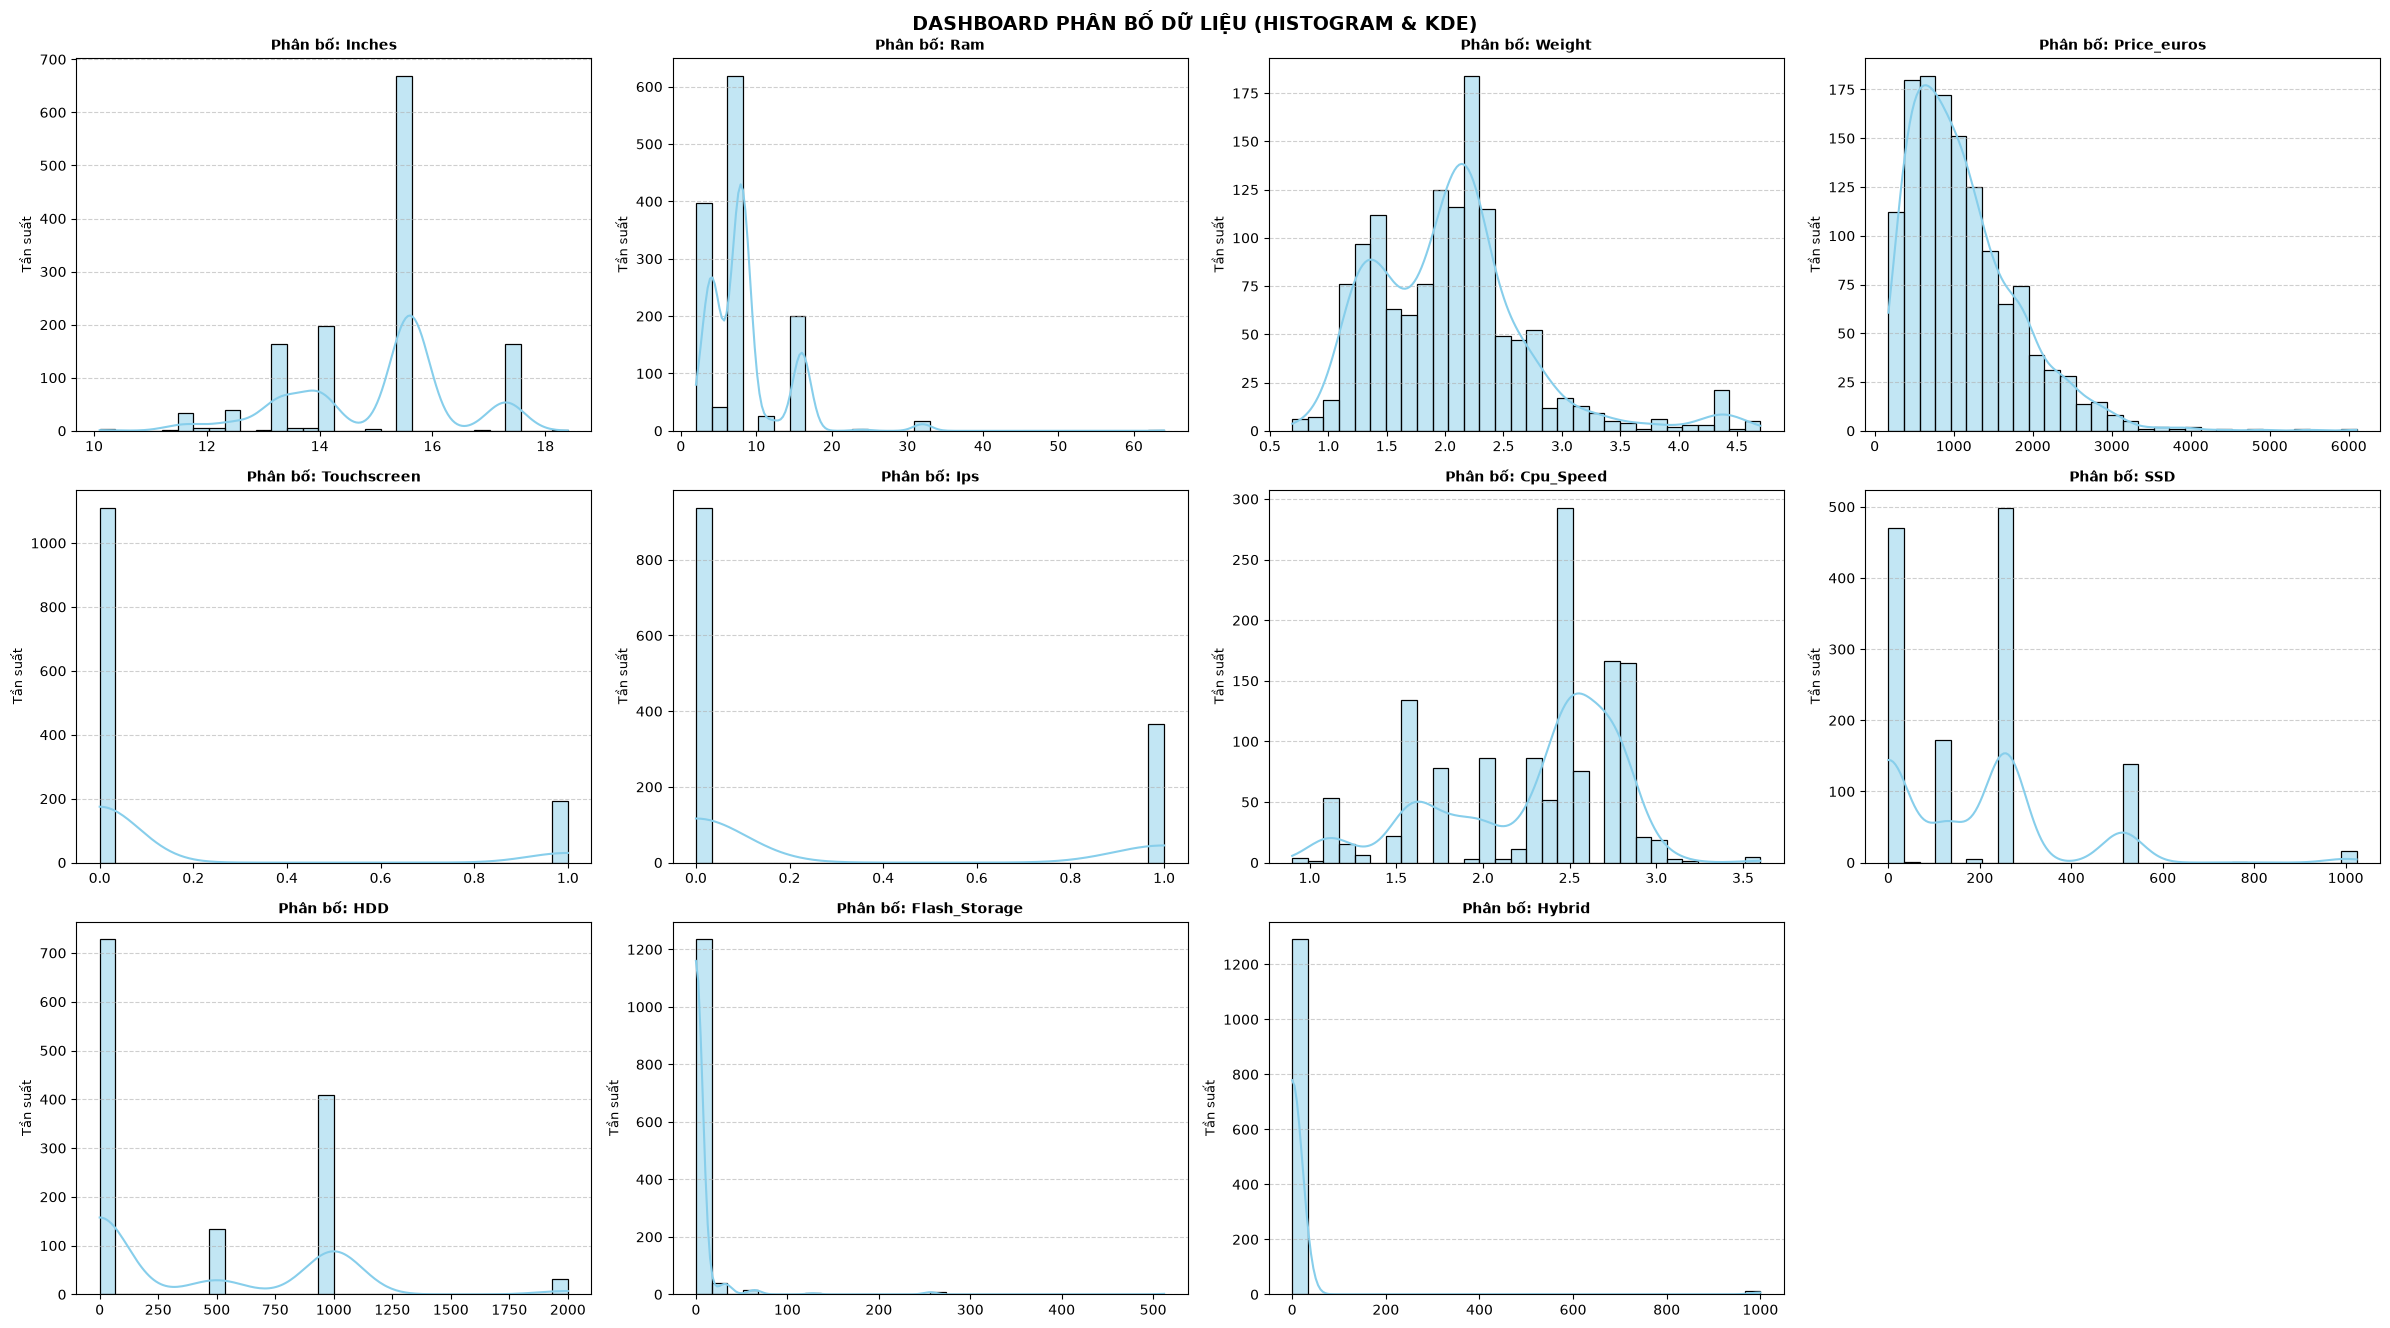

In [6]:
numeric_var_statistic(df, numerical_cols=numerical_cols)

=== Tần suất cho biến: Company ===
           Số lượng  Tỷ lệ (%)
Company                       
Dell            297  22.793553
Lenovo          297  22.793553
HP              274  21.028396
Asus            158  12.125863
Acer            103   7.904835
MSI              54   4.144282
Toshiba          48   3.683807
Apple            21   1.611665
Samsung           9   0.690714
Razer             7   0.537222
Mediacom          7   0.537222
Microsoft         6   0.460476
Xiaomi            4   0.306984
Vero              4   0.306984
Chuwi             3   0.230238
Google            3   0.230238
Fujitsu           3   0.230238
LG                3   0.230238
Huawei            2   0.153492
----------------------------------------
=== Tần suất cho biến: TypeName ===
                    Số lượng  Tỷ lệ (%)
TypeName                               
Notebook                 727  55.794321
Gaming                   205  15.732924
Ultrabook                196  15.042210
2 in 1 Convertible       121   9.2862

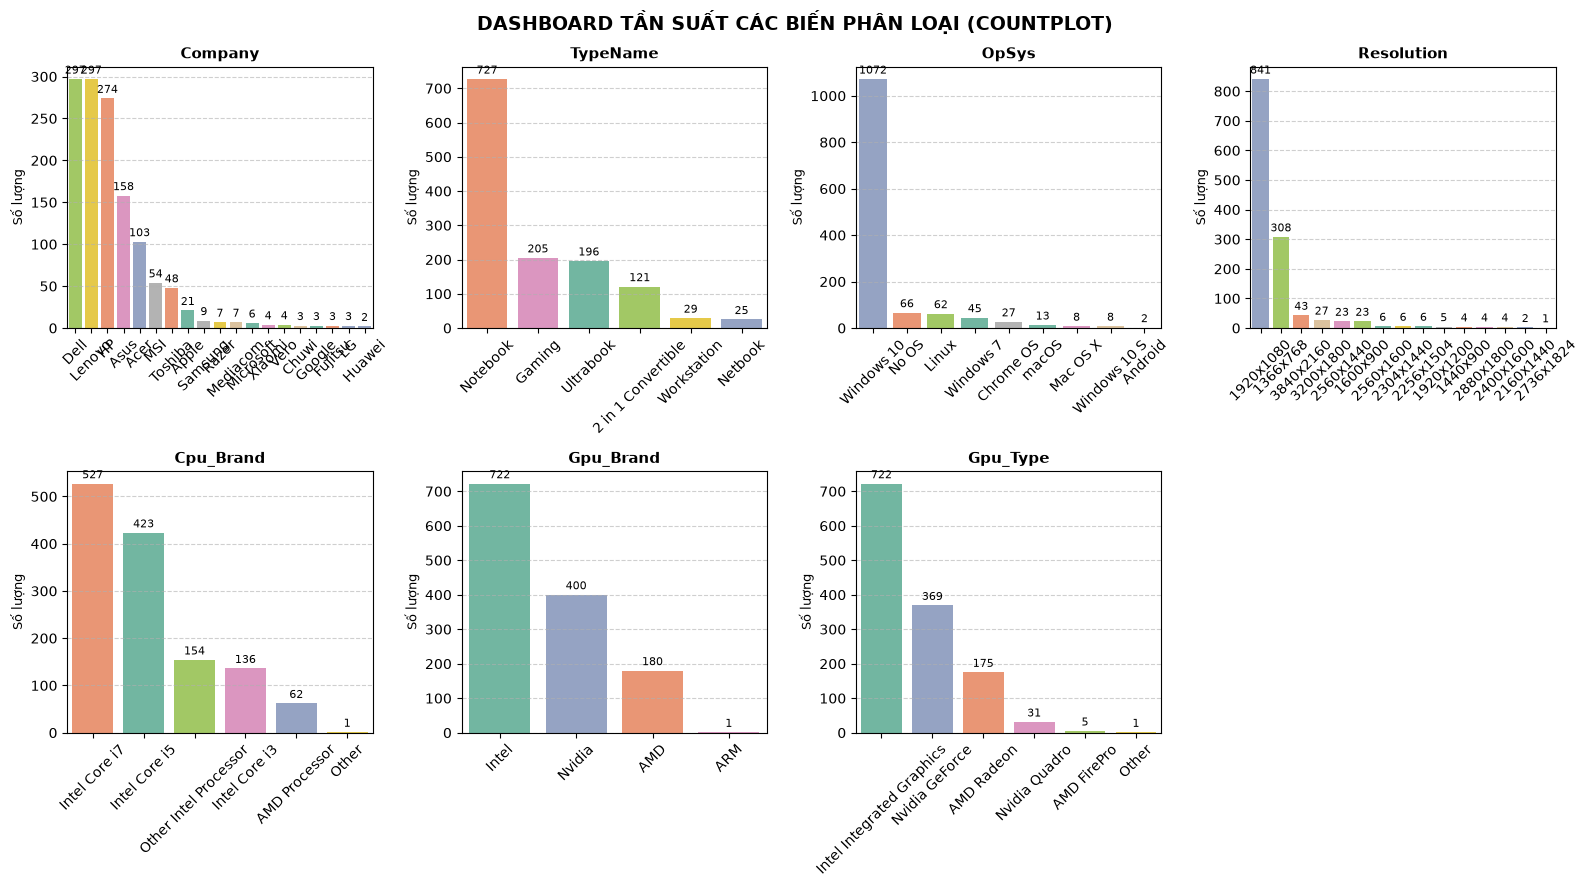

In [7]:
categorical_var_statistic(df, categorical_cols=categorical_cols)

In [8]:
df = remove_outliner(df, ["Price_euros"])
df.head(3)

[THÀNH CÔNG] Xóa ngoại lệ hoàn tất! Kích thước: 1274 dòng, 18 cột.


,Company,TypeName,Inches,Ram,OpSys,Weight,Price_euros,Touchscreen,Ips,Resolution,Cpu_Speed,Cpu_Brand,SSD,HDD,Flash_Storage,Hybrid,Gpu_Brand,Gpu_Type
0,Apple,Ultrabook,13.3,8,macOS,1.37,1339.69,0,1,2560x1600,2.3,Intel Core i5,128,0,0,0,Intel,Intel Integrated Graphics
1,Apple,Ultrabook,13.3,8,macOS,1.34,898.94,0,0,1440x900,1.8,Intel Core i5,0,0,128,0,Intel,Intel Integrated Graphics
2,HP,Notebook,15.6,8,No OS,1.86,575.00,0,0,1920x1080,2.5,Intel Core i5,256,0,0,0,Intel,Intel Integrated Graphics


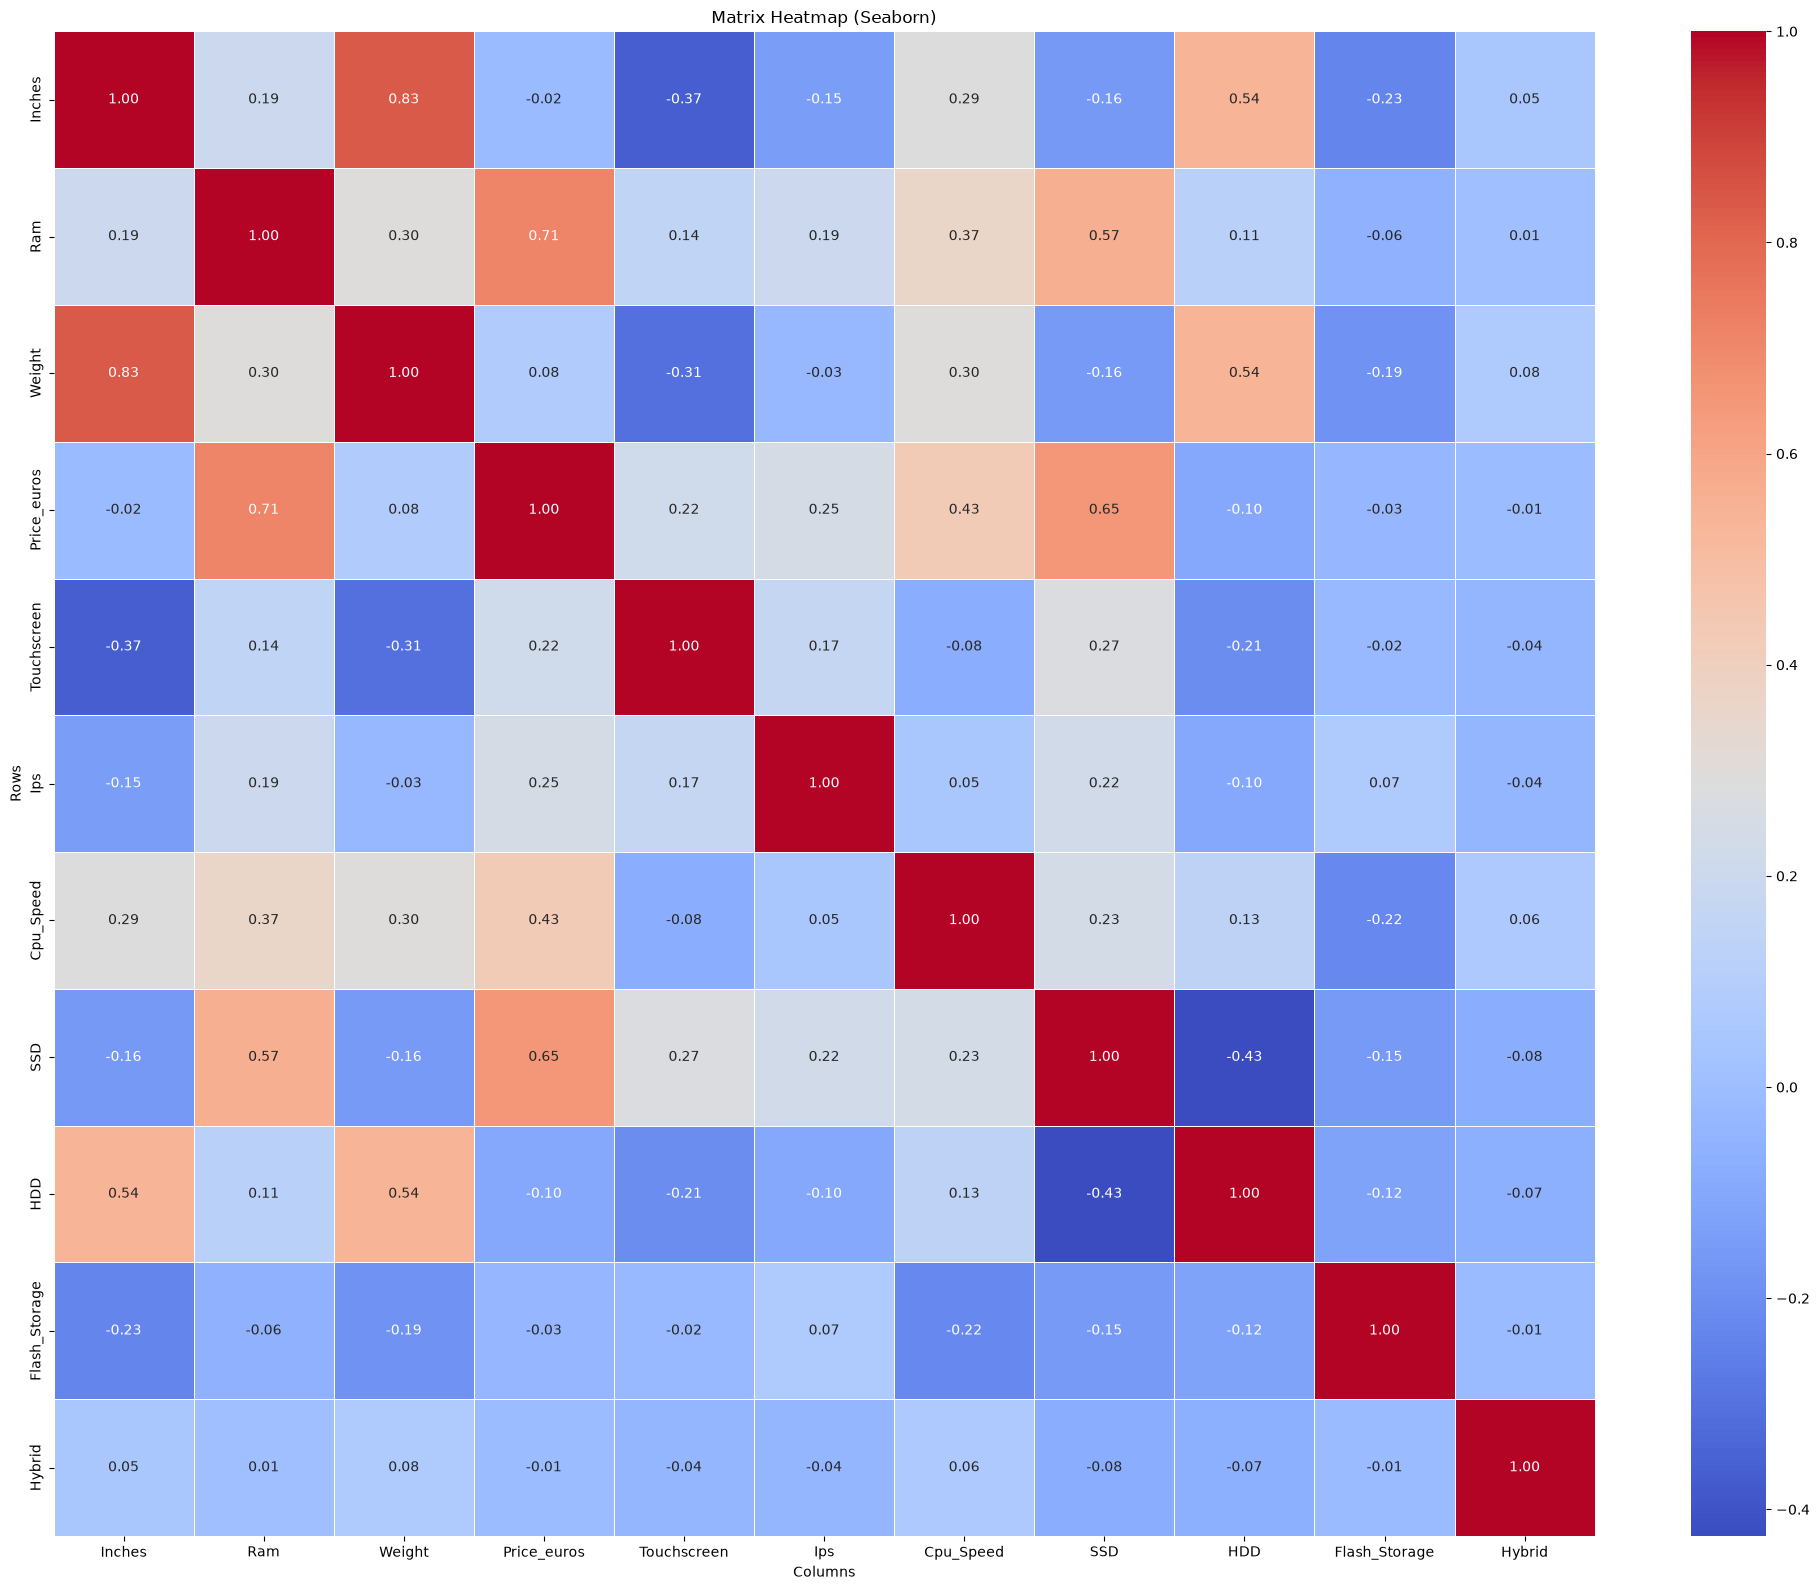

Các cột có |corr| > 0.2 với Price_euros:
['Ram', 'Touchscreen', 'Ips', 'Cpu_Speed', 'SSD']


In [9]:
numerical = select_numberical_variable(
    df, series_name=numerical_cols, target='Price_euros', alpha=0.2
)

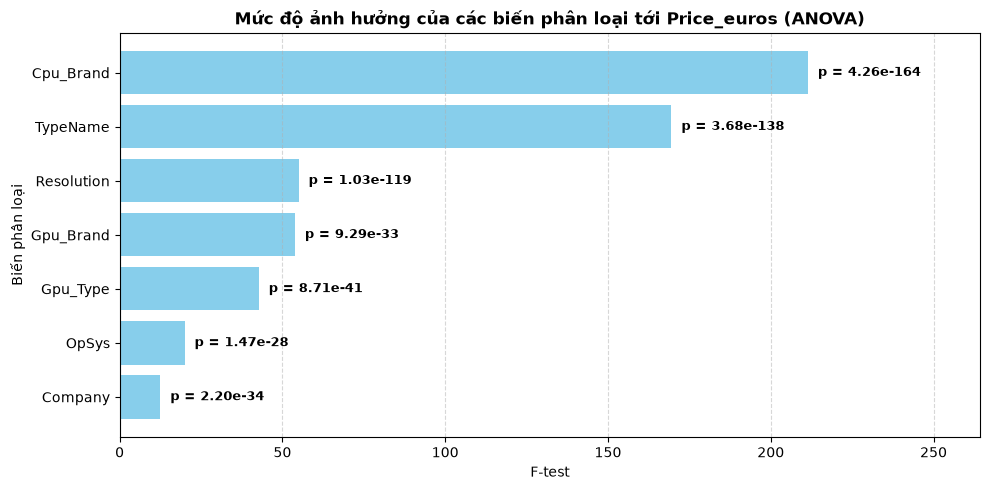

In [10]:
categorical = select_categorical_variable(df, categorical_cols)
plot_anova(df, series=categorical_cols, target="Price_euros", alpha=0.05)

In [11]:
procesed_df = preprocess_data(df, categorical, numerical, ignore_col=["Ips","Touchscreen"])

Đang tiến hành tiền xử lý dữ liệu ...
[THÀNH CÔNG] Tiền xử lý hoàn tất! Kích thước dữ liệu mới: 1274 dòng, 64 cột.


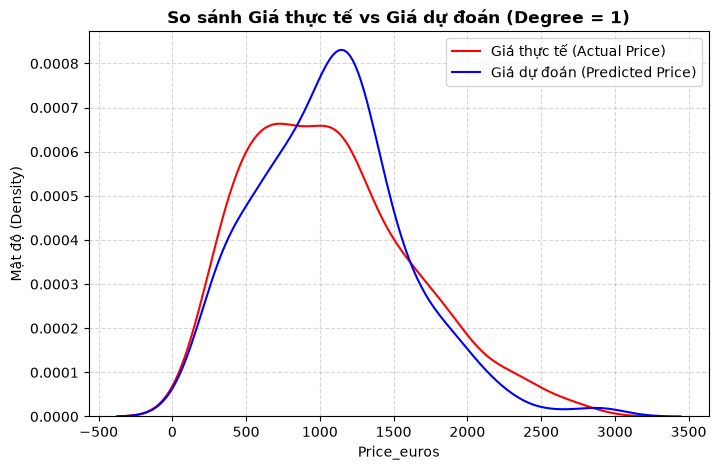

(0.7968093656804662, 0.772454337828808)


In [12]:
print(train_data_pipeline(procesed_df, degree=1))